In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import pickle

import sys
sys.path.append('../../../')

# Import methods
from QGP.Soliton_Gen import *
from Utilities import *

import config

i = 1j

# Bright solitons

## Standing

In [82]:
path_bright = "../../../Heaven_scripts/Results/Errors/Bright/"
path_bright_time = "../../../Heaven_scripts/Results/Errors/Bright/time_order_2/"

In [83]:
theo = pickle.load(open(path_bright + "theo_bright_w_0.71_k_0.25_L_40.pck", "rb"))

In [84]:
order = 2
tf = 5
L = 40

Ns = np.array([500, 1_000, 2_000, 5_000, 10_000, 50_000, 100_000]) 

dts = np.array([2**(-j) for j in range(2, 14)]) # 1, 11
Nts = tf/dts

base = "errors_N_"
folders = []
errors_br_stat = []
for N in Ns:
    folder_name = path_bright_time + base + "{N}_order_{o}/".format(N=N, o=2)
    folders += [folder_name]
    e_file = gzip.GzipFile(folder_name + "error.npy.gz", "r")
    error = np.load(e_file)
    errors_br_stat += [error]

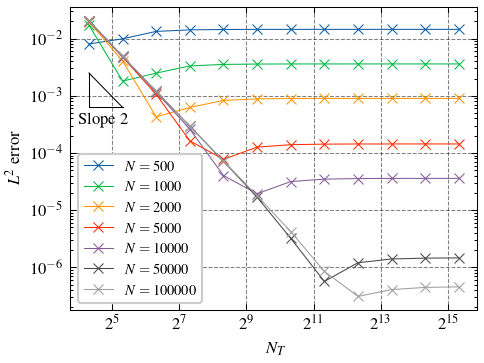

In [85]:
#dts = tf/Nts
for j in range(len(Ns)):
    N = Ns[j]
    plt.plot(Nts, errors_br_stat[j], "x-", lw=.5, markeredgewidth=.5, ms=5, label=r"$N = {}$".format(N))

Nt_order_1 = Nts[:2]
order_1 = (1/Nt_order_1)**2*np.exp(0)
plt.plot(Nt_order_1, order_1, color="black", lw=.5, ls="-")
plt.plot(Nt_order_1, np.tile(order_1[-1], len(Nt_order_1)), color="black", lw=.5, ls="-")
plt.plot(np.tile(Nt_order_1[0], len(order_1)), order_1, color="black", lw=.5, ls="-")

plt.text(np.mean(Nt_order_1[:1])-2**2, order_1[-1]-3e-4, r'Slope 2')

plt.legend(fontsize=7)
plt.xscale("log", base=2)
plt.yscale("log")

plt.xlabel(r"$N_T$")
plt.ylabel(r"$L^2$ error")

#plt.savefig("Img/Errors_Heaven/Bright/Static/Bright_NT_L_40_w_0.71_k_0.25.pdf", dpi=300, bbox_inches = "tight")
#plt.savefig("Img/Errors_Heaven/Bright/Static/Bright_NT_L_40_w_0.71_k_0.25.pgf", dpi=300, bbox_inches = "tight")
plt.show()

In [86]:
EOCs = []

dic_EOC = {}
for n in range(len(Ns)):
    EOC = []
    for j in range(len(Nts)-1):
        EOC += [np.log2(errors_br_stat[n][j]/errors_br_stat[n][j+1])]
        #EOC_2 += [np.log2(errors[1][j]/errors[1][j+1])]
        #EOC_3 += [np.log2(errors[2][j]/errors[2][j+1])]
        #EOC_4 += [np.log2(errors[3][j]/errors[3][j+1])]
        #EOC_5 += [np.log2(errors[4][j]/errors[4][j+1])]
    dic_EOC["$N={}$".format(Ns[n])] = EOC

df_EOC = pd.DataFrame(dic_EOC)

df_EOC.index = list(Nts)[:-1]
print(df_EOC)
#df_EOC.to_latex(float_format="%.3f", buf="Img/Errors_Heaven/Bright/EOC_tab_stat_NT_L_40_w_0.71_k_0.25.txt")

          $N=500$  $N=1000$  $N=2000$  $N=5000$  $N=10000$  $N=50000$  \
20.0    -0.300762  3.242909  2.283140  2.100610   2.076999   2.069563   
40.0    -0.429760 -0.461880  3.235199  2.169645   2.067318   2.036669   
80.0    -0.089709 -0.416140 -0.543322  2.696261   2.153357   2.022955   
160.0   -0.021361 -0.088458 -0.409578  1.076719   2.691547   2.029527   
320.0   -0.005258 -0.021224 -0.087862 -0.712757   1.058090   2.089447   
640.0   -0.001307 -0.005243 -0.021162 -0.140424  -0.709614   2.389074   
1280.0  -0.000326 -0.001306 -0.005237 -0.033227  -0.140173   2.504075   
2560.0  -0.000081 -0.000326 -0.001306 -0.008193  -0.033201  -1.085644   
5120.0  -0.000020 -0.000081 -0.000326 -0.002041  -0.008190  -0.216959   
10240.0 -0.000005 -0.000020 -0.000081 -0.000510  -0.002041  -0.050261   
20480.0 -0.000001 -0.000005 -0.000020 -0.000127  -0.000510  -0.012334   

         $N=100000$  
20.0       2.069331  
40.0       2.035727  
80.0       2.019144  
160.0      2.014067  
320.0      2.

## Moving

In [120]:
path_bright = "../../../Heaven_scripts/Results/Errors/Bright/"
path_bright_time_mov = "../../../Heaven_scripts/Results/Errors/Bright/moving_time_order_2/"

In [121]:
theo = pickle.load(open(path_bright + "theo_bright_c_0.71_k_0.25_w_1_L_100.pck", "rb"))

In [122]:
order = 2
tf = 5
L = 100

Ns = np.array([5_000, 10_000, 50_000, 100_000]) 

dts = np.array([2**(-j) for j in range(2, 14)]) # 1, 11
Nts = tf/dts

base = "errors_N_"
folders = []
errors_br_moving = []
for N in Ns:
    folder_name = path_bright_time_mov + base + "{N}_order_{o}/".format(N=N, o=2)
    folders += [folder_name]
    e_file = gzip.GzipFile(folder_name + "error.npy.gz", "r")
    error = np.load(e_file)
    errors_br_moving += [error]

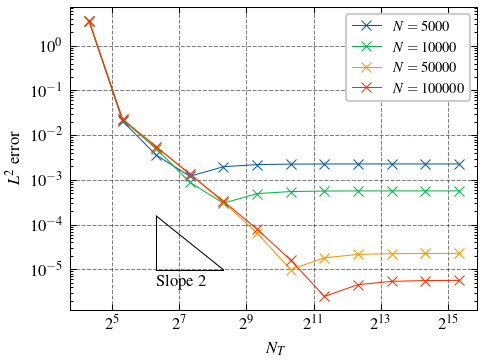

In [126]:
#dts = tf/Nts
for j in range(len(Ns)):
    N = Ns[j]
    plt.plot(Nts, errors_br_moving[j][1:], "x-", lw=.5, markeredgewidth=.5, ms=5, label=r"$N = {}$".format(N))

Nt_order_1 = Nts[2:5]
order_1 = (1/Nt_order_1)**2*np.exp(0)
plt.plot(Nt_order_1, order_1, color="black", lw=.5, ls="-")
plt.plot(Nt_order_1, np.tile(order_1[-1], len(Nt_order_1)), color="black", lw=.5, ls="-")
plt.plot(np.tile(Nt_order_1[0], len(order_1)), order_1, color="black", lw=.5, ls="-")

plt.text(np.mean(Nt_order_1[:1]), order_1[-1]-5.5e-6, r'Slope 2')

plt.legend(fontsize=7)
plt.xscale("log", base=2)
plt.yscale("log")

plt.xlabel(r"$N_T$")
plt.ylabel(r"$L^2$ error")

#plt.savefig("Img/Errors_Heaven/Bright/Moving/Bright_NT_L_100_c_0.71_k_0.25_w_1.pdf", dpi=300, bbox_inches = "tight")
#plt.savefig("Img/Errors_Heaven/Bright/Moving/Bright_NT_L_100_c_0.71_k_0.25_w_1.pgf", dpi=300, bbox_inches = "tight")
plt.show()

In [91]:
EOCs = []

dic_EOC = {}
for n in range(len(Ns)):
    EOC = []
    for j in range(len(Nts)-1):
        EOC += [np.log2(errors_br_moving[n][j]/errors_br_moving[n][j+1])]
        #EOC_2 += [np.log2(errors[1][j]/errors[1][j+1])]
        #EOC_3 += [np.log2(errors[2][j]/errors[2][j+1])]
        #EOC_4 += [np.log2(errors[3][j]/errors[3][j+1])]
        #EOC_5 += [np.log2(errors[4][j]/errors[4][j+1])]
    dic_EOC["$N={}$".format(Ns[n])] = EOC

df_EOC = pd.DataFrame(dic_EOC)

df_EOC.index = list(Nts)[:-1]
print(df_EOC)
#df_EOC.to_latex(float_format="%.3f", buf="Img/Errors_Heaven/Bright/EOC_tab_mov_NT_L_40_w_0.71_k_0.25.txt")

           $N=5000$   $N=10000$   $N=50000$  $N=100000$
20.0     223.132859  190.747344  199.672401  200.582878
40.0       7.462541    7.360584    7.329083    7.328107
80.0       2.512232    2.139194    2.037231    2.034182
160.0      1.577723    2.501261    2.033813    2.021431
320.0     -0.714126    1.546965    2.076505    2.025394
640.0     -0.154530   -0.709183    2.299873    2.072265
1280.0    -0.036688   -0.153974    2.704676    2.297822
2560.0    -0.009046   -0.036627   -0.875823    2.693917
5120.0    -0.002253   -0.009039   -0.248434   -0.870292
10240.0   -0.000562   -0.002252   -0.057667   -0.247607
20480.0   -0.000141   -0.000562   -0.014146   -0.057522


# Dark soliton Errors in $D_1$

In [99]:
path_D1 = "../../../Heaven_scripts/Results/Errors/D1/"
path_D1_time = "../../../Heaven_scripts/Results/Errors/D1/time_order_2/"
path_D1_L = "../../../Heaven_scripts/Results/Errors/D1/time_order_2_L_100/"

## $L=40$

In [78]:
theo = pickle.load(open(path_D1 + "theo_c_0.71_k_0.25.pck", "rb"))
c = np.sqrt(2)/2
def theo_dark(x, t):
    output = theo(x - c*t)
    return output

In [79]:
order = 2
tf = 5
L = 40
dts = np.array([2**(-j) for j in range(1, 14)]) #dts = np.array([2**(-j) for j in range(3, 11)]) 
Nts = tf/dts

Ns = np.array([500, 1_000, 2_000, 5_000, 10_000, 50_000, 100_000])# 100_000  #np.array([5_001, 10_001, 50_001, 100_001])

base = "errors_N_"
folders = []
errors = []
for N in Ns:
    folder_name = path_D1_time + base + "{N}_order_{o}/".format(N=N, o=2)
    folders += [folder_name]
    e_file = gzip.GzipFile(folder_name + "error.npy.gz", "r")
    error = np.load(e_file)
    errors += [error]

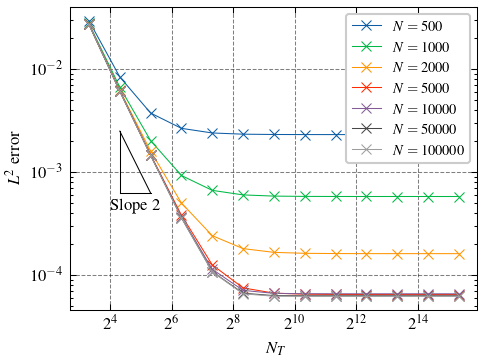

In [80]:
#dts = tf/Nts
for j in range(len(Ns)):
    N = Ns[j]
    plt.plot(Nts, errors[j], "x-", lw=.5, markeredgewidth=.5, ms=5, label=r"$N = {}$".format(N))

Nt_order_1 = Nts[1:3]
order_1 = (1/Nt_order_1)**2*np.exp(0)
plt.plot(Nt_order_1, order_1, color="black", lw=.5, ls="-")
plt.plot(Nt_order_1, np.tile(order_1[-1], len(Nt_order_1)), color="black", lw=.5, ls="-")
plt.plot(np.tile(Nt_order_1[0], len(order_1)), order_1, color="black", lw=.5, ls="-")

plt.text(np.mean(Nt_order_1[:1])-2**2, order_1[-1]-2e-4, r'Slope 2')

plt.legend(fontsize=7)
plt.xscale("log", base=2)
plt.yscale("log")

plt.xlabel(r"$N_T$")
plt.ylabel(r"$L^2$ error")

plt.savefig("Img/Errors_Heaven/Dark_D1/Dark_D1_NT_L_40_c_0.70_k_0.25.pdf", dpi=600, bbox_inches = "tight")
plt.savefig("Img/Errors_Heaven/Dark_D1/Dark_D1_NT_L_40_c_0.70_k_0.25.pgf", dpi=600, bbox_inches = "tight")
plt.show()

In [81]:
EOCs = []

dic_EOC = {}
for n in range(len(Ns)):
    EOC = []
    for j in range(len(Nts)-1):
        EOC += [np.log2(errors[n][j]/errors[n][j+1])]
        #EOC_2 += [np.log2(errors[1][j]/errors[1][j+1])]
        #EOC_3 += [np.log2(errors[2][j]/errors[2][j+1])]
        #EOC_4 += [np.log2(errors[3][j]/errors[3][j+1])]
        #EOC_5 += [np.log2(errors[4][j]/errors[4][j+1])]
    dic_EOC["$N={}$".format(Ns[n])] = EOC

df_EOC = pd.DataFrame(dic_EOC)

df_EOC.index = list(Nts)[:-1]
print(df_EOC)
df_EOC.to_latex(float_format="%.3f", buf="Img/Errors_Heaven/Dark_D1/EOC_tab_D1_NT_L_40_c_0.70_k_0.25.txt")

          $N=500$  $N=1000$  $N=2000$  $N=5000$  $N=10000$     $N=50000$  \
10.0     1.814102  2.056603  2.128746  2.149979   2.153033  2.154022e+00   
20.0     1.165000  1.726480  1.972615  2.056595   2.068957  2.073120e+00   
40.0     0.493840  1.124000  1.671545  1.952959   1.997516  2.014991e+00   
80.0     0.149328  0.480220  1.053781  1.604231   1.684541  1.738583e+00   
160.0    0.039172  0.146268  0.418252  0.742959   0.681338  6.963286e-01   
320.0    0.009880  0.038579  0.120599  0.169064   0.095716  7.723384e-02   
640.0    0.002471  0.009762  0.031197  0.034858   0.012053  5.330437e-03   
1280.0   0.000617  0.002446  0.007858  0.008081   0.002180  3.958958e-04   
2560.0   0.000154  0.000611  0.001967  0.001977   0.000492  4.032212e-05   
5120.0   0.000039  0.000153  0.000492  0.000491   0.000120  6.418804e-06   
10240.0  0.000010  0.000038  0.000123  0.000123   0.000030  1.375897e-06   
20480.0  0.000002  0.000010  0.000031  0.000031   0.000007  3.296611e-07   

           

## $L=100$

In [100]:
theo = pickle.load(open(path_D1 + "theo_c_0.71_k_0.25_L_100.pck", "rb"))
c = np.sqrt(2)/2
def theo_dark(x, t):
    output = theo(x - c*t)
    return output

In [101]:
order = 2
tf = 5
L = 100
dts = np.array([2**(-j) for j in range(1, 14)]) #dts = np.array([2**(-j) for j in range(3, 11)]) 
Nts = tf/dts

Ns = np.array([500, 1_000, 2_000, 5_000, 10_000, 50_000, 100_000])# 100_000  #np.array([5_001, 10_001, 50_001, 100_001])

base = "errors_N_"
folders = []
errors_dark_D1_L_100 = []
for N in Ns:
    folder_name = path_D1_L + base + "{N}_order_{o}/".format(N=N, o=2)
    folders += [folder_name]
    e_file = gzip.GzipFile(folder_name + "error.npy.gz", "r")
    error = np.load(e_file)
    errors_dark_D1_L_100 += [error]

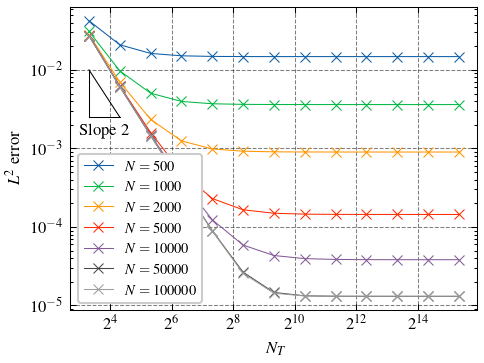

In [102]:
#dts = tf/Nts
for j in range(len(Ns)):
    N = Ns[j]
    plt.plot(Nts, errors_dark_D1_L_100[j], "x-", lw=.5, markeredgewidth=.5, ms=5, label=r"$N = {}$".format(N))

Nt_order_1 = Nts[:2]
order_1 = (1/Nt_order_1)**2*np.exp(0)
plt.plot(Nt_order_1, order_1, color="black", lw=.5, ls="-")
plt.plot(Nt_order_1, np.tile(order_1[-1], len(Nt_order_1)), color="black", lw=.5, ls="-")
plt.plot(np.tile(Nt_order_1[0], len(order_1)), order_1, color="black", lw=.5, ls="-")

plt.text(np.mean(Nt_order_1[:1])-2, order_1[-1]-1e-3, r'Slope 2')

plt.legend(fontsize=7)
plt.xscale("log", base=2)
plt.yscale("log")

plt.xlabel(r"$N_T$")
plt.ylabel(r"$L^2$ error")

#plt.savefig("Img/Errors_Heaven/Dark_D1/Dark_D1_NT_L_100_c_0.70_k_0.25.pdf", dpi=600, bbox_inches = "tight")
#plt.savefig("Img/Errors_Heaven/Dark_D1/Dark_D1_NT_L_100_c_0.70_k_0.25.pgf", dpi=600, bbox_inches = "tight")
plt.show()

In [103]:
EOCs = []

dic_EOC = {}
for n in range(len(Ns)):
    EOC = []
    for j in range(len(Nts)-1):
        EOC += [np.log2(errors_dark_D1_L_100[n][j]/errors_dark_D1_L_100[n][j+1])]
    dic_EOC["$N={}$".format(Ns[n])] = EOC

df_EOC = pd.DataFrame(dic_EOC)

df_EOC.index = list(Nts)[:-1]
print(df_EOC)
#df_EOC.to_latex(float_format="%.3f", buf="Img/Errors_Heaven/Dark_D1/EOC_tab_D1_NT_L_100_c_0.70_k_0.25.txt")

              $N=500$  $N=1000$  $N=2000$  $N=5000$  $N=10000$  $N=50000$  \
10.0     1.016087e+00  1.670058  2.006133  2.128851   2.147750   2.153875   
20.0     3.652843e-01  0.942372  1.581905  1.974049   2.048345   2.073443   
40.0     1.007226e-01  0.349193  0.907289  1.685339   1.933869   2.031442   
80.0     2.549361e-02  0.098627  0.341043  1.106435   1.657821   1.986590   
160.0    6.346862e-03  0.025318  0.097450  0.476294   1.069382   1.759114   
320.0    1.579268e-03  0.006349  0.025190  0.146022   0.442093   0.854575   
640.0    3.936336e-04  0.001586  0.006340  0.038663   0.131393   0.143853   
1280.0   9.824493e-05  0.000396  0.001586  0.009802   0.034396   0.018917   
2560.0   2.453984e-05  0.000099  0.000396  0.002458   0.008696   0.003448   
5120.0   6.132225e-06  0.000025  0.000099  0.000615   0.002180   0.000780   
10240.0  1.532711e-06  0.000006  0.000025  0.000154   0.000545   0.000190   
20480.0  3.831350e-07  0.000002  0.000006  0.000038   0.000136   0.000047   

# Stable dark solitons Errors in $D_2$

In [111]:
path_D2 = "../../../Heaven_scripts/Results/Errors/D2/"
path_D2_time = "../../../Heaven_scripts/Results/Errors/D2/time_order_2/"
path_D2_L = "../../../Heaven_scripts/Results/Errors/D2/time_order_2_L_200/"

## $L=100$

In [86]:
k = -50
pars = {"k":k}
c_0 = np.sqrt(2)/2

P_p_ = lambda c: P_p(c, k)
P_pp_ = lambda c: P_pp(c, k)

c_star, error = newton_1D(c_0, P_p_, P_pp_)

eps = 0.1
c = c_star + eps

In [87]:
theo = pickle.load(open(path_D2 + "theo_c_0.57_k_-50_L_100.pck", "rb"))
def theo_dark(x, t):
    output = theo(x - c*t)
    return output

In [88]:
order = 2
tf = 5
L = 100
dts = np.array([2**(-j) for j in range(1, 14)]) #dts = np.array([2**(-j) for j in range(3, 11)]) 
Nts = tf/dts

Ns = np.array([500, 1_000, 2_000, 5_000, 10_000, 50_000, 100_000])# 100_000  #np.array([5_001, 10_001, 50_001, 100_001])

base = "errors_N_"
folders = []
errors = []
for N in Ns:
    folder_name = path_D2_time + base + "{N}_order_{o}/".format(N=N, o=2)
    folders += [folder_name]
    e_file = gzip.GzipFile(folder_name + "error.npy.gz", "r")
    error = np.load(e_file)
    errors += [error]

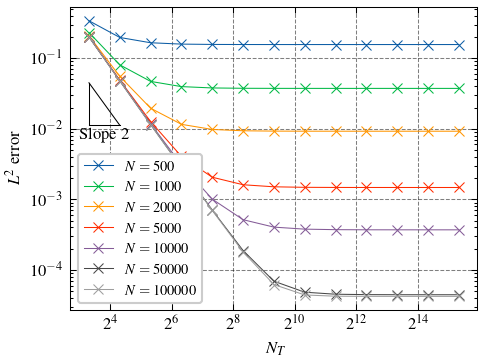

In [93]:
#dts = tf/Nts
for j in range(len(Ns)):
    N = Ns[j]
    plt.plot(Nts, errors[j], "x-", lw=.5, markeredgewidth=.5, ms=5, label=r"$N = {}$".format(N))

Nt_order_1 = Nts[:2]
order_1 = (1/Nt_order_1)**2*np.exp(1.5)
plt.plot(Nt_order_1, order_1, color="black", lw=.5, ls="-")
plt.plot(Nt_order_1, np.tile(order_1[-1], len(Nt_order_1)), color="black", lw=.5, ls="-")
plt.plot(np.tile(Nt_order_1[0], len(order_1)), order_1, color="black", lw=.5, ls="-")

plt.text(np.mean(Nt_order_1[:1])-2, order_1[-1]-4e-3, r'Slope 2')

plt.legend(fontsize=7)
plt.xscale("log", base=2)
plt.yscale("log")

plt.xlabel(r"$N_T$")
plt.ylabel(r"$L^2$ error")

plt.savefig("Img/Errors_Heaven/Dark_D2/Dark_D2_NT_L_100_k_-50_eps_0.1.pdf", dpi=600, bbox_inches = "tight")
plt.savefig("Img/Errors_Heaven/Dark_D2/Dark_D2_NT_L_100_k_-50_eps_0.1.pgf", dpi=600, bbox_inches = "tight")
plt.show()

In [94]:
EOCs = []

dic_EOC = {}
for n in range(len(Ns)):
    EOC = []
    for j in range(len(Nts)-1):
        EOC += [round(np.log2(errors[n][j]/errors[n][j+1]), 4)]
        #EOC_2 += [np.log2(errors[1][j]/errors[1][j+1])]
        #EOC_3 += [np.log2(errors[2][j]/errors[2][j+1])]
        #EOC_4 += [np.log2(errors[3][j]/errors[3][j+1])]
        #EOC_5 += [np.log2(errors[4][j]/errors[4][j+1])]
    dic_EOC["$N={}$".format(Ns[n])] = EOC

df_EOC = pd.DataFrame(dic_EOC)

df_EOC.index = list(Nts)[:-1]
print(df_EOC)
df_EOC.to_latex(float_format="%.3f", buf="Img/Errors_Heaven/Dark_D2/EOC_tab_D2_NT_L_100_k_-50_eps_0.1.txt")

         $N=500$  $N=1000$  $N=2000$  $N=5000$  $N=10000$  $N=50000$  \
10.0      0.7860    1.5214    1.9113    2.0447     2.0644     2.0708   
20.0      0.2489    0.7790    1.4979    1.9494     2.0291     2.0553   
40.0      0.0635    0.2447    0.7585    1.6402     1.9236     2.0278   
80.0      0.0157    0.0630    0.2401    0.9785     1.6216     1.9969   
160.0     0.0038    0.0158    0.0627    0.3543     0.9667     1.9038   
320.0     0.0009    0.0039    0.0157    0.0964     0.3493     1.4433   
640.0     0.0002    0.0010    0.0039    0.0244     0.0950     0.5171   
1280.0    0.0001    0.0002    0.0010    0.0061     0.0241     0.0954   
2560.0    0.0000    0.0001    0.0002    0.0015     0.0060     0.0187   
5120.0    0.0000    0.0000    0.0001    0.0004     0.0015     0.0043   
10240.0   0.0000    0.0000    0.0000    0.0001     0.0004     0.0010   
20480.0   0.0000    0.0000    0.0000    0.0000     0.0001     0.0003   

         $N=100000$  
10.0         2.0710  
20.0         2.0561

## $L=200$

In [112]:
theo = pickle.load(open(path_D2 + "theo_c_0.57_k_-50_L_200.pck", "rb"))
def theo_dark(x, t):
    output = theo(x - c*t)
    return output

In [113]:
order = 2
tf = 5
L = 200
dts = np.array([2**(-j) for j in range(1, 14)]) #dts = np.array([2**(-j) for j in range(3, 11)]) 
Nts = tf/dts

Ns = np.array([500, 1_000, 2_000, 5_000, 10_000, 50_000, 100_000])# 100_000  #np.array([5_001, 10_001, 50_001, 100_001])

base = "errors_N_"
folders = []
errors_dark_D2_L_200 = []
for N in Ns:
    folder_name = path_D2_L + base + "{N}_order_{o}/".format(N=N, o=2)
    folders += [folder_name]
    e_file = gzip.GzipFile(folder_name + "error.npy.gz", "r")
    error = np.load(e_file)
    errors_dark_D2_L_200 += [error]

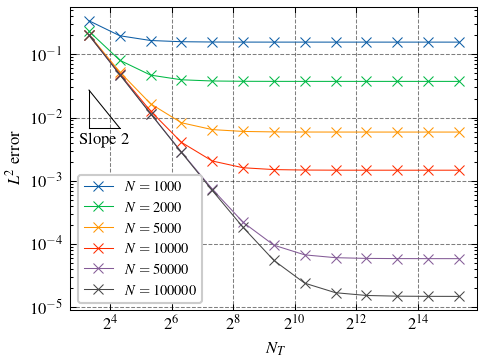

In [114]:
#dts = tf/Nts
for j in range(1, len(Ns)):
    N = Ns[j]
    plt.plot(Nts, errors_dark_D2_L_200[j], "x-", lw=.5, markeredgewidth=.5, ms=5, label=r"$N = {}$".format(N))

Nt_order_1 = Nts[:2]
order_1 = (1/Nt_order_1)**2*np.exp(1)
plt.plot(Nt_order_1, order_1, color="black", lw=.5, ls="-")
plt.plot(Nt_order_1, np.tile(order_1[-1], len(Nt_order_1)), color="black", lw=.5, ls="-")
plt.plot(np.tile(Nt_order_1[0], len(order_1)), order_1, color="black", lw=.5, ls="-")

plt.text(np.mean(Nt_order_1[:1])-2, order_1[-1]-3e-3, r'Slope 2')

plt.legend(fontsize=7)
plt.xscale("log", base=2)
plt.yscale("log")

plt.xlabel(r"$N_T$")
plt.ylabel(r"$L^2$ error")

#plt.savefig("Img/Errors_Heaven/Dark_D2/Dark_D2_NT_L_200_k_-50_eps_0.1.pdf", dpi=600, bbox_inches = "tight")
#plt.savefig("Img/Errors_Heaven/Dark_D2/Dark_D2_NT_L_200_k_-50_eps_0.1.pgf", dpi=600, bbox_inches = "tight")
plt.show()

In [115]:
EOCs = []

dic_EOC = {}
for n in range(len(Ns)):
    EOC = []
    for j in range(len(Nts)-1):
        EOC += [round(np.log2(errors_dark_D2_L_200[n][j]/errors_dark_D2_L_200[n][j+1]), 4)]
    dic_EOC["$N={}$".format(Ns[n])] = EOC

df_EOC = pd.DataFrame(dic_EOC)

df_EOC.index = list(Nts)[:-1]
print(df_EOC)
#df_EOC.to_latex(float_format="%.3f", buf="Img/Errors_Heaven/Dark_D2/EOC_tab_D2_NT_L_200_k_-50_eps_0.1.txt")

         $N=500$  $N=1000$  $N=2000$  $N=5000$  $N=10000$  $N=50000$  \
10.0     -1.1333    0.7871    1.5218    1.9673     2.0447     2.0700   
20.0     -1.2294    0.2494    0.7795    1.6689     1.9494     2.0520   
40.0      7.1467    0.0636    0.2449    0.9948     1.6403     2.0146   
80.0     -0.0026    0.0157    0.0632    0.3585     0.9789     1.9463   
160.0    -0.0007    0.0039    0.0158    0.0970     0.3545     1.7416   
320.0     0.0003    0.0010    0.0039    0.0245     0.0965     1.2008   
640.0     0.0001    0.0002    0.0010    0.0061     0.0245     0.5084   
1280.0    0.0000    0.0001    0.0002    0.0015     0.0061     0.1473   
2560.0    0.0000    0.0000    0.0001    0.0004     0.0015     0.0379   
5120.0    0.0000    0.0000    0.0000    0.0001     0.0004     0.0095   
10240.0   0.0000    0.0000    0.0000    0.0000     0.0001     0.0024   
20480.0   0.0000    0.0000    0.0000    0.0000     0.0000     0.0006   

         $N=100000$  
10.0         2.0708  
20.0         2.0553

# Comparison

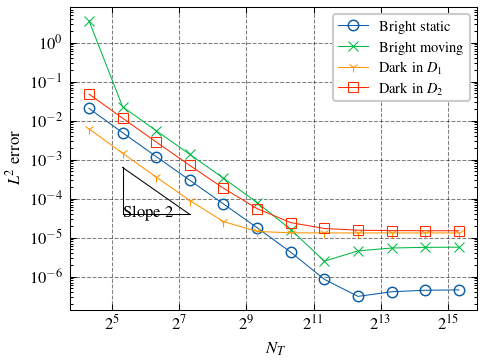

In [119]:
#dts = tf/Nts

N = Ns[-1]
plt.plot(Nts[1:], errors_br_stat[-1], "o-", markerfacecolor="none", lw=.5, markeredgewidth=.7, ms=5, label="Bright static")
plt.plot(Nts[1:], errors_br_moving[-1][1:], "x-", lw=.5, markeredgewidth=.5, ms=5, label="Bright moving")
plt.plot(Nts[1:], errors_dark_D1_L_100[-1][1:], "1-", lw=.5, markeredgewidth=.5, ms=5, label=r"Dark in $D_1$")
plt.plot(Nts[1:], errors_dark_D2_L_200[-1][1:], "s-", markerfacecolor="none", lw=.5, markeredgewidth=.5, ms=5, label=r"Dark in $D_2$")

Nt_order_1 = Nts[2:5]
order_1 = (1/Nt_order_1)**2*np.exp(0)
plt.plot(Nt_order_1, order_1, color="black", lw=.5, ls="-")
plt.plot(Nt_order_1, np.tile(order_1[-1], len(Nt_order_1)), color="black", lw=.5, ls="-")
plt.plot(np.tile(Nt_order_1[0], len(order_1)), order_1, color="black", lw=.5, ls="-")

plt.text(np.mean(Nt_order_1[:1]), order_1[-1]-5.5e-6, r'Slope 2')

plt.legend(fontsize=7)
plt.xscale("log", base=2)
plt.yscale("log")

plt.xlabel(r"$N_T$")
plt.ylabel(r"$L^2$ error")

#plt.savefig("Img/Errors_Heaven/Bright/Moving/Bright_NT_L_100_c_0.71_k_0.25_w_1.pdf", dpi=300, bbox_inches = "tight")
#plt.savefig("Img/Errors_Heaven/Bright/Moving/Bright_NT_L_100_c_0.71_k_0.25_w_1.pgf", dpi=300, bbox_inches = "tight")
plt.show()